# Handwritten Digit Recognition with PyTorch



## 1. Import libraries

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from google.colab import files

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load and prepare the MNIST dataset



In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(
    root="data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="data", train=False, download=True, transform=transform
)

train_size = 55000
val_size = 5000
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training images:   {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Test images:       {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 605kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.56MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 17.6MB/s]

Training images:   55000
Validation images: 5000
Test images:       10000


## 3. Visualize sample images

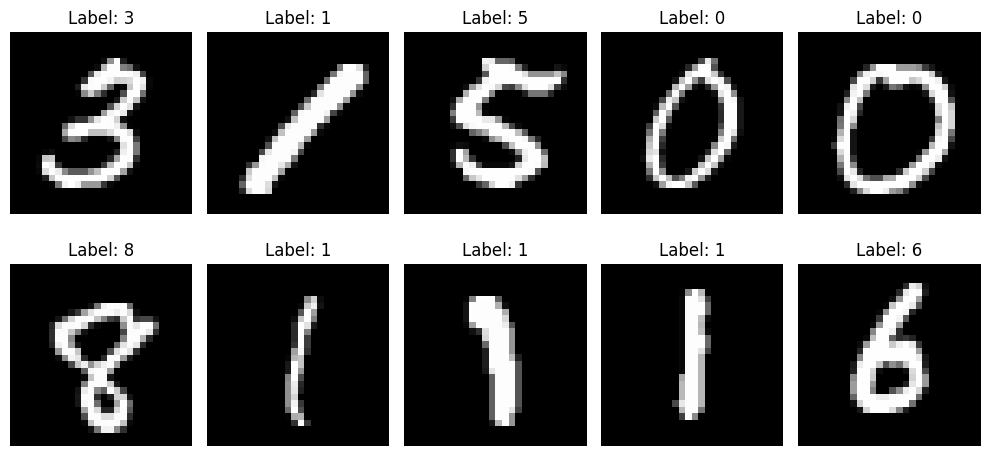

Batch image shape: torch.Size([64, 1, 28, 28])


In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    # Undo normalization for display
    image = images[i].squeeze() * 0.3081 + 0.1307
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Batch image shape:", images.shape)  # (batch_size, 1, 28, 28)

## 4. Build the neural network



In [ ]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

model = DigitClassifier().to(device)
print(model)

DigitClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 5. Set the loss function and optimizer

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15
PATIENCE = 4

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 6. Train and validate the model

In [ ]:
def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": []
}

best_val_accuracy = 0.0
best_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2%} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2%}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation accuracy did not improve.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

print(f"Best validation accuracy: {best_val_accuracy:.2%}")

Epoch [1/15] | Train Loss: 0.3548 | Train Acc: 89.32% | Val Loss: 0.1768 | Val Acc: 94.84%
Epoch [2/15] | Train Loss: 0.1742 | Train Acc: 94.75% | Val Loss: 0.1357 | Val Acc: 95.82%
Epoch [3/15] | Train Loss: 0.1355 | Train Acc: 95.94% | Val Loss: 0.1073 | Val Acc: 96.76%
Epoch [4/15] | Train Loss: 0.1174 | Train Acc: 96.34% | Val Loss: 0.1046 | Val Acc: 96.96%
Epoch [5/15] | Train Loss: 0.1058 | Train Acc: 96.78% | Val Loss: 0.0986 | Val Acc: 97.12%
Epoch [6/15] | Train Loss: 0.0952 | Train Acc: 97.08% | Val Loss: 0.0839 | Val Acc: 97.52%
Epoch [7/15] | Train Loss: 0.0865 | Train Acc: 97.28% | Val Loss: 0.0953 | Val Acc: 97.16%
Epoch [8/15] | Train Loss: 0.0832 | Train Acc: 97.52% | Val Loss: 0.0889 | Val Acc: 97.40%
Epoch [9/15] | Train Loss: 0.0758 | Train Acc: 97.64% | Val Loss: 0.0991 | Val Acc: 97.18%
Epoch [10/15] | Train Loss: 0.0699 | Train Acc: 97.77% | Val Loss: 0.0965 | Val Acc: 97.36%
Early stopping: validation accuracy did not improve.
Best validation accuracy: 97.52%


## 7. Plot training history

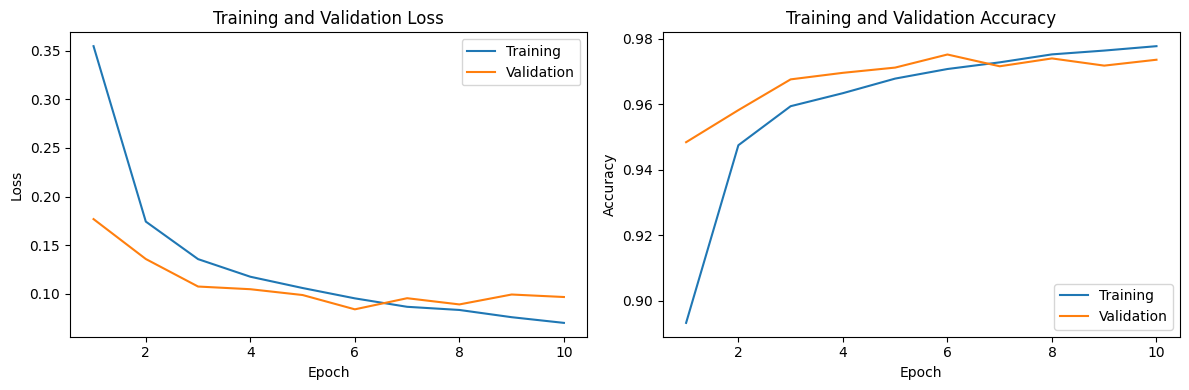

In [ ]:
epochs_completed = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_completed, history["train_loss"], label="Training")
plt.plot(epochs_completed, history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_completed, history["train_accuracy"], label="Training")
plt.plot(epochs_completed, history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## 8. Evaluate on the test set



In [ ]:
test_loss, test_accuracy = run_epoch(test_loader, training=False)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss:     0.0750
Test Accuracy: 97.67%


## 9. Save the trained model

In [ ]:
os.makedirs("models", exist_ok=True)

checkpoint_path = "models/best_model.pth"
torch.save(model.state_dict(), checkpoint_path)

print("Model saved to:", checkpoint_path)

# Optional: download the trained weights to your computer
files.download(checkpoint_path)

Model saved to: models/best_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Predict a digit from your own image

Upload an image containing **one handwritten digit**. For best results:
- Use a clear, high-contrast image.
- The digit should be centered and occupy most of the image.
- The notebook converts it to grayscale and resizes it to 28×28.
- MNIST images have a dark background and a light digit. If your image has a light background with dark writing, the code automatically inverts it based on average brightness.

This simple preprocessing is intended for clean, single-digit images; unusual backgrounds or off-center digits may reduce accuracy.

In [1]:
uploaded = files.upload()

def preprocess_uploaded_image(image_path):
    image = Image.open(image_path).convert("L")

    # Make the digit light on a dark background when needed.
    if np.array(image).mean() > 127:
        image = ImageOps.invert(image)

    image = image.resize((28, 28))
    image_tensor = transforms.ToTensor()(image)
    image_tensor = transforms.Normalize((0.1307,), (0.3081,))(image_tensor)
    return image_tensor.unsqueeze(0)

model.eval()

for filename in uploaded.keys():
    input_tensor = preprocess_uploaded_image(filename).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)
        predicted_digit = probabilities.argmax(dim=1).item()
        confidence = probabilities[0, predicted_digit].item()

    display_image = Image.open(filename).convert("L")
    plt.figure(figsize=(3, 3))
    plt.imshow(display_image, cmap="gray")
    plt.title(f"Prediction: {predicted_digit} ({confidence:.2%} confidence)")
    plt.axis("off")
    plt.show()

    print(f"{filename} → Predicted digit: {predicted_digit}")
    print(f"Confidence: {confidence:.2%}")

NameError: name 'files' is not defined